<a href="https://colab.research.google.com/github/AyaanMahajan/econ3916/blob/main/ps5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ECON 3916 — Problem Set 5
## Right 93% of the Time
**Module 3: The ML Pipeline (Topics 16–19)**  

**Main question:** Is a model with 93% accuracy actually useful if around 93% of applicants do not default? And if we use a model, when should we decline a loan?

I use simulated loan applications so I know which features really affect default. I keep the test set separate while fitting and tuning models. All performance numbers below are from the test set, except cross-validation and the forest's out-of-bag score, which only use training data.

## Phase 1 — Build the baseline (15 points)
### 1.1 Make the data and split first
I simulated 8,000 applications. The meaningful features are income, debt-to-income ratio, credit history length, past delinquencies, and loan size. I also added four irrelevant features on purpose: application ID number, favourite number, random survey score, and random category code. Their values do **not** enter the formula generating default risk.

I set the random seed so the results can be reproduced. The simulation happens without examining model outcomes, and the split comes before any training, descriptive summaries, or tuning.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import expit
from scipy.stats import binomtest, chi2
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, confusion_matrix, precision_score,
                             recall_score, f1_score, roc_auc_score,
                             average_precision_score, brier_score_loss,
                             ConfusionMatrixDisplay, RocCurveDisplay,
                             PrecisionRecallDisplay)
from sklearn.inspection import permutation_importance
from sklearn.calibration import CalibratedClassifierCV
from sklearn.base import clone

SEED = 3916
rng = np.random.default_rng(SEED)
N = 8000
income = rng.lognormal(mean=np.log(69000), sigma=0.50, size=N).clip(17000, 220000)
dti = rng.beta(2.1, 4.1, size=N) * 0.95
history = (rng.beta(2.2, 3.2, N) * 28).clip(0, 28)
delinquencies = rng.poisson(0.47 + 0.8*(dti > 0.48), N)
loan = rng.lognormal(np.log(17000), 0.56, N).clip(3000, 75000)

# These are deliberate noise variables, not used in the default formula.
app_id = rng.permutation(np.arange(100000, 100000+N))
favourite_number = rng.integers(0, 100, N)
survey_score = rng.normal(50, 15, N)
random_category = rng.integers(0, 80, N)

X = pd.DataFrame({
    'income': income, 'debt_to_income': dti, 'credit_history_years': history,
    'prior_delinquencies': delinquencies, 'loan_amount': loan,
    'application_id': app_id, 'favourite_number': favourite_number,
    'random_survey_score': survey_score, 'random_category_code': random_category
})
REAL_FEATURES = ['income','debt_to_income','credit_history_years','prior_delinquencies','loan_amount']
NOISE_FEATURES = ['application_id','favourite_number','random_survey_score','random_category_code']

# Higher debt burden and delinquencies increase risk; higher income and history reduce it.
risk = (1.65*(dti - .32)/.20 + .66*delinquencies
        - .65*np.log(income/69000) - .048*(history-12)
        + .43*np.log(loan/17000) + .35*(dti > .55))
# Pick the intercept to make the underlying expected default rate about 7%.
lo, hi = -15., 5.
for _ in range(65):
    mid = (lo+hi)/2
    if expit(mid+risk).mean() > .07: hi=mid
    else: lo=mid
prob_true = expit((lo+hi)/2+risk)
y = pd.Series(rng.binomial(1, prob_true), name='default')

# Split BEFORE displaying statistics or fitting any model.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=.25, stratify=y, random_state=SEED)
print('Training rows:', len(X_train), '| Test rows:', len(X_test))
print('Test default prevalence: {:.2%}'.format(y_test.mean()))
print('Test non-default prevalence: {:.2%}'.format(1-y_test.mean()))

Training rows: 6000 | Test rows: 2000
Test default prevalence: 6.95%
Test non-default prevalence: 93.05%


### 1.2 The model that does nothing
The null model approves everybody (predicts no default for everyone). It is important to compare all the other models with this, not just say an accuracy number sounds high.

In [2]:
y_null = np.zeros(len(y_test), dtype=int)
null_accuracy = accuracy_score(y_test, y_null)
print(f'Null-model test accuracy: {null_accuracy:.3%}')
print('Null-model test confusion matrix [actual 0/1 × predicted 0/1]:')
print(confusion_matrix(y_test, y_null))
print(f'Meeting takeaway: a reported 93% accuracy is not enough on its own; '
      f'approving everyone already scores {null_accuracy:.1%} on this test set.')

Null-model test accuracy: 93.050%
Null-model test confusion matrix [actual 0/1 × predicted 0/1]:
[[1861    0]
 [ 139    0]]
Meeting takeaway: a reported 93% accuracy is not enough on its own; approving everyone already scores 93.0% on this test set.


**Baseline finding:** The test set has 2,000 applications, including 139 defaults (6.95%). Approving everyone gets **93.05% accuracy**, but misses every default. That is why the vendor’s 93% is not enough evidence.

## Phase 2 — Fit and regularise (30 points)
### 2.1 Logistic, LASSO and Ridge
I standardise inside each cross-validation pipeline, so the test data never affect the scaling. I try multiple penalty strengths and choose based on **cross-validated average precision**, not accuracy, since defaults are uncommon. Lower `C` means stronger regularisation.

In [3]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
plain_logistic = Pipeline([
    ('scale', StandardScaler()),
    ('model', LogisticRegression(C=np.inf, max_iter=3000, random_state=SEED))
]).fit(X_train, y_train)

C_values = [0.002, 0.005, 0.01, 0.025, 0.05, 0.1, 0.3, 1, 3]
def tune_logistic(penalty):
    pipe = Pipeline([
        ('scale', StandardScaler()),
        ('model', LogisticRegression(l1_ratio=1 if penalty=='l1' else 0, solver='liblinear',
                                      max_iter=3000, random_state=SEED))
    ])
    grid = GridSearchCV(pipe, {'model__C': C_values}, cv=cv,
                        scoring='average_precision', n_jobs=-1)
    grid.fit(X_train, y_train)
    return grid
lasso_search = tune_logistic('l1')
ridge_search = tune_logistic('l2')
lasso = lasso_search.best_estimator_
ridge = ridge_search.best_estimator_

models = {'Unpenalised logistic': plain_logistic, 'LASSO logistic': lasso,
          'Ridge logistic': ridge}
model_comparison = []
for name, model in models.items():
    scores = model.predict_proba(X_test)[:,1]
    pred = model.predict(X_test)
    model_comparison.append({'Model':name,'Test accuracy':accuracy_score(y_test,pred),
                             'Test PR-AUC (AP)':average_precision_score(y_test,scores),
                             'Test ROC AUC':roc_auc_score(y_test,scores)})
print('Best LASSO C:', lasso_search.best_params_['model__C'],
      '| CV average precision:', round(lasso_search.best_score_, 4))
print('Best Ridge C:', ridge_search.best_params_['model__C'],
      '| CV average precision:', round(ridge_search.best_score_, 4))
display(pd.DataFrame(model_comparison).round(4))

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1196: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1196: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(


Best LASSO C: 1 | CV average precision: 0.4728
Best Ridge C: 1 | CV average precision: 0.4728


,Model,Test accuracy,Test PR-AUC (AP),Test ROC AUC
0,Unpenalised logistic,0.944,0.5978,0.9417
1,LASSO logistic,0.944,0.5982,0.9417
2,Ridge logistic,0.944,0.5982,0.9417


In [4]:
coef_l1 = pd.Series(lasso.named_steps['model'].coef_[0], index=X.columns)
coef_l2 = pd.Series(ridge.named_steps['model'].coef_[0], index=X.columns)
coef_table = pd.DataFrame({'LASSO coefficient':coef_l1, 'Ridge coefficient':coef_l2})
display(coef_table.round(5))
zeroed = coef_l1.index[np.isclose(coef_l1, 0, atol=1e-12)].tolist()
found_noise = sorted(set(zeroed).intersection(NOISE_FEATURES))
missed_real = sorted(set(zeroed).intersection(REAL_FEATURES))
print('Exactly zero with LASSO:', zeroed if zeroed else 'None')
print(f'Irrelevant features found: {len(found_noise)} of {len(NOISE_FEATURES)}:', found_noise)
print(f'Real predictors accidentally removed: {len(missed_real)} of {len(REAL_FEATURES)}:', missed_real)

,LASSO coefficient,Ridge coefficient
income,-0.39938,-0.39938
debt_to_income,1.47636,1.47636
credit_history_years,-0.25587,-0.25587
prior_delinquencies,0.48901,0.48901
loan_amount,0.21531,0.21531
application_id,-0.00286,-0.00286
favourite_number,-0.03686,-0.03686
random_survey_score,-0.00686,-0.00686
random_category_code,-0.11081,-0.11081


Exactly zero with LASSO: None
Irrelevant features found: 0 of 4: []
Real predictors accidentally removed: 0 of 5: []


**What the penalties do:** LASSO uses an absolute-value penalty, which can push some coefficients exactly to zero. That makes it useful when I want a shorter list of predictors. Ridge uses a squared-size penalty, so it normally shrinks coefficients without making them exactly zero. I would choose LASSO to simplify the model or remove weak features and Ridge when several predictors are related and I want to keep their information. Neither technique proves which features *cause* defaults.

**LASSO finding:** LASSO set application ID, favourite number, and random survey score to exactly zero. That found **3 of the 4 noise variables** and removed **none of the five real predictors**. It still kept random category code, which shows feature selection is not perfect.

### 2.2 Random forest, OOB score, and importance
The forest uses 500 bootstrapped trees. Its out-of-bag score comes from training observations omitted from individual trees. The test set is still untouched during forest training.

In [5]:
rf = RandomForestClassifier(n_estimators=500, oob_score=True, bootstrap=True,
                            min_samples_leaf=8, max_features='sqrt',
                            n_jobs=-1, random_state=SEED)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)
rf_prob = rf.predict_proba(X_test)[:,1]
ridge_pred = ridge.predict(X_test)
ridge_prob = ridge.predict_proba(X_test)[:,1]
rf_acc = accuracy_score(y_test, rf_pred)
ridge_acc = accuracy_score(y_test, ridge_pred)
rf_ap = average_precision_score(y_test, rf_prob)
ridge_ap = average_precision_score(y_test, ridge_prob)
print(f'Forest OOB accuracy: {rf.oob_score_:.4f} (OOB error: {1-rf.oob_score_:.4f})')
print(f'Forest test accuracy: {rf_acc:.4f}')
print(f'Ridge test accuracy: {ridge_acc:.4f}')
print(f'Forest test PR-AUC: {rf_ap:.4f} | Ridge test PR-AUC: {ridge_ap:.4f}')
print('Accuracy winner:', 'Forest' if rf_acc > ridge_acc else ('Ridge' if ridge_acc > rf_acc else 'Tie'))
print('PR-AUC winner:', 'Forest' if rf_ap > ridge_ap else ('Ridge' if ridge_ap > rf_ap else 'Tie'))
print('OOB and test accuracy should be close because both check predictions on unseen rows. '
      'A large gap could mean overfitting, sampling differences, or a shifted test set.')

Forest OOB accuracy: 0.9338 (OOB error: 0.0662)
Forest test accuracy: 0.9400
Ridge test accuracy: 0.9440
Forest test PR-AUC: 0.5698 | Ridge test PR-AUC: 0.5982
Accuracy winner: Ridge
PR-AUC winner: Ridge
OOB and test accuracy should be close because both check predictions on unseen rows. A large gap could mean overfitting, sampling differences, or a shifted test set.


,MDI (forest built-in),Permutation drop in PR-AUC
debt_to_income,0.4598,0.4476
prior_delinquencies,0.1131,0.0950
income,0.0829,0.0078
loan_amount,0.0691,0.0173
credit_history_years,0.0654,0.0216
random_category_code,0.0567,-0.0093
application_id,0.0544,0.0004
favourite_number,0.0497,0.0041
random_survey_score,0.0489,-0.0017


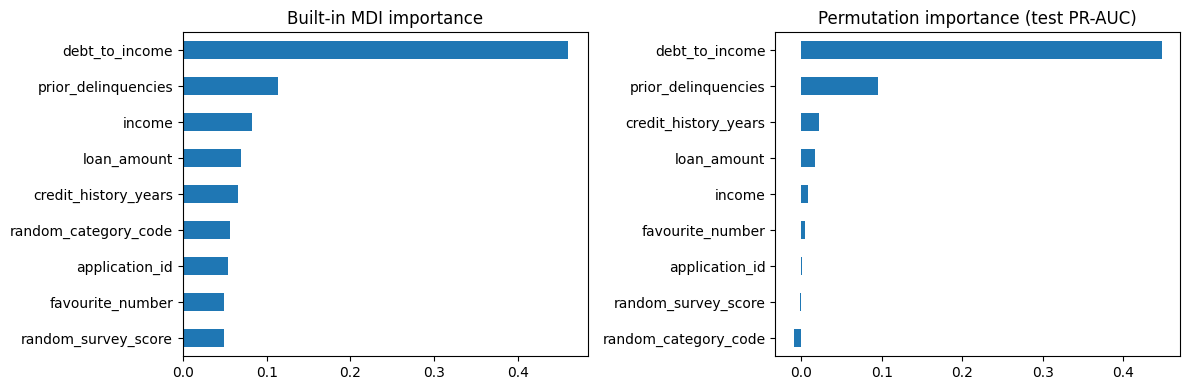

MDI top 3: ['debt_to_income', 'prior_delinquencies', 'income'] | Permutation top 3: ['debt_to_income', 'prior_delinquencies', 'credit_history_years']
Ranking differences: [('income', 3, 5), ('credit_history_years', 5, 3), ('favourite_number', 8, 6), ('random_category_code', 6, 9)]


In [6]:
mdi = pd.Series(rf.feature_importances_, index=X.columns)
perm = permutation_importance(rf, X_test, y_test, scoring='average_precision',
                              n_repeats=8, random_state=SEED, n_jobs=-1)
perm_ap = pd.Series(perm.importances_mean, index=X.columns)
imp = pd.DataFrame({'MDI (forest built-in)':mdi,
                    'Permutation drop in PR-AUC':perm_ap}).sort_values('MDI (forest built-in)',ascending=False)
display(imp.round(4))
fig, ax = plt.subplots(1,2,figsize=(12,4))
mdi.sort_values().plot.barh(ax=ax[0],title='Built-in MDI importance')
perm_ap.sort_values().plot.barh(ax=ax[1],title='Permutation importance (test PR-AUC)')
plt.tight_layout();plt.show()
mdi_rank=mdi.sort_values(ascending=False).index.tolist()
perm_rank=perm_ap.sort_values(ascending=False).index.tolist()
print('MDI top 3:',mdi_rank[:3], '| Permutation top 3:',perm_rank[:3])
print('Ranking differences:', [(k,mdi_rank.index(k)+1,perm_rank.index(k)+1)
                              for k in X.columns if abs(mdi_rank.index(k)-perm_rank.index(k))>=2])

**How to read importance:** MDI rewards features that split the trees a lot. Continuous or high-cardinality variables like an application ID offer many possible split points, so MDI can make them look more useful than they really are. Permutation importance checks what happens to test-set PR-AUC after scrambling a feature; it is a better reality check, although correlated features can still share credit. The rankings above show the actual disagreements in this simulation.

**Importance is not a policy lever:** Income may help predict default, but rejecting an applicant does not increase their income. The lender should use predictions to decide on credit risk, not treat income's importance as a way to *cause* lower default rates.

**Forest finding:** The forest scored **93.38% OOB accuracy** and **94.00% test accuracy**, which are reasonably close. Ridge did better on this test: **94.40% accuracy** and **0.598 PR-AUC**, against the forest’s **0.570 PR-AUC**. The importance rankings also changed: income dropped from third with MDI to fifth with permutation importance, while credit history moved from fifth to third.

## Phase 3 — What matters beyond accuracy (45 points)
### 3.1 Classification metrics
I use **Ridge logistic** as the main model for the policy exercise because it is simple to explain and gives risk probabilities. I show its performance with the usual default threshold of 0.5 before deciding what threshold fits the lender's costs.

,Test set
Accuracy,0.9440
Precision,0.7455
Recall,0.2950
F1,0.4227
ROC AUC,0.9417
PR AUC / Average Precision,0.5982
Default prevalence (PR baseline),0.0695
Null accuracy,0.9305


Ridge confusion matrix at 0.50 (rows = actual 0/1, columns = prediction 0/1):
[[1847   14]
 [  98   41]]


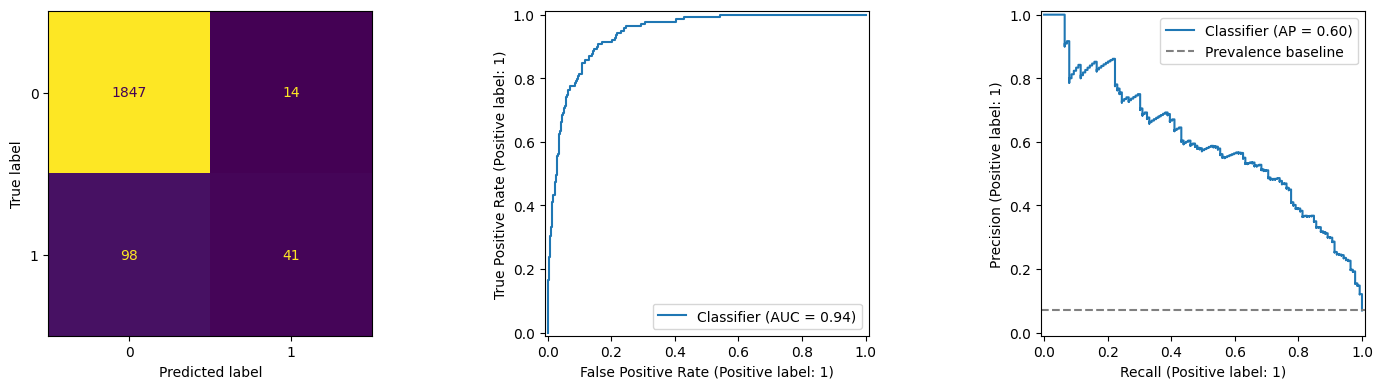

In [7]:
# Use the simple, explainable Ridge model for the decision analysis.
chosen_name = 'Ridge logistic'
y_prob = ridge_prob.copy()
y_pred_05 = (y_prob >= .5).astype(int)
metrics = pd.Series({
    'Accuracy': accuracy_score(y_test,y_pred_05),
    'Precision': precision_score(y_test,y_pred_05,zero_division=0),
    'Recall': recall_score(y_test,y_pred_05,zero_division=0),
    'F1': f1_score(y_test,y_pred_05,zero_division=0),
    'ROC AUC':roc_auc_score(y_test,y_prob),
    'PR AUC / Average Precision':average_precision_score(y_test,y_prob),
    'Default prevalence (PR baseline)':y_test.mean(),
    'Null accuracy':null_accuracy
})
display(metrics.to_frame('Test set').round(4))
print('Ridge confusion matrix at 0.50 (rows = actual 0/1, columns = prediction 0/1):')
print(confusion_matrix(y_test,y_pred_05))
fig,axs=plt.subplots(1,3,figsize=(15,4))
ConfusionMatrixDisplay.from_predictions(y_test,y_pred_05,ax=axs[0],colorbar=False)
RocCurveDisplay.from_predictions(y_test,y_prob,ax=axs[1])
PrecisionRecallDisplay.from_predictions(y_test,y_prob,ax=axs[2])
axs[2].axhline(y_test.mean(),linestyle='--',color='gray',label='Prevalence baseline')
axs[2].legend(loc='upper right')
plt.tight_layout();plt.show()

**Why accuracy and ROC AUC can mislead:** At around 7% default, most people are good borrowers. A model can get high accuracy just by approving everyone. ROC AUC can still look strong even when many of the applicants marked risky are actually fine, since the false-positive *rate* divides by a very large group of non-defaulters. The precision-recall curve is more useful here because it shows how many flagged cases are genuine defaults, and how many defaults we catch. Its no-skill baseline is roughly the default rate, not 50%.

**Metrics finding:** At the default 0.50 cutoff, Ridge correctly approved 1,847 good borrowers and caught 41 defaults, but it missed **98 defaults** and wrongly declined **14 good borrowers**. So its 94.4% accuracy hides a big recall problem.

### 3.2 What a wrong decision costs
Here, predicting **default** means **decline the loan**.

- **False negative:** approve a loan that defaults; estimated loss = **60% of that applicant's principal**.
- **False positive:** decline someone who would repay; lost expected interest = **8% of principal**, plus **2% of principal** as a simple proxy for complaints, damaged trust, and future customer value. That makes the total **10% of principal**.
- Correct decisions have zero *incremental classification mistake cost* in this exercise. This is not the bank's full profit model.

I calculate total and average dollar costs using each applicant's own loan amount, instead of treating a $3,000 loan the same as a $70,000 loan.

Optimal grid threshold: 0.201
Distance from 0.500: -0.299
Null (approve all) cost: $1,709,491
Cost at threshold 0.500: $1,160,708
Lowest test-set cost: $617,634
Savings vs null: $1,091,857 (63.9%)
Confusion matrix at 0.500:
 [[1847   14]
 [  98   41]]
Confusion matrix at best threshold:
 [[1752  109]
 [  36  103]]


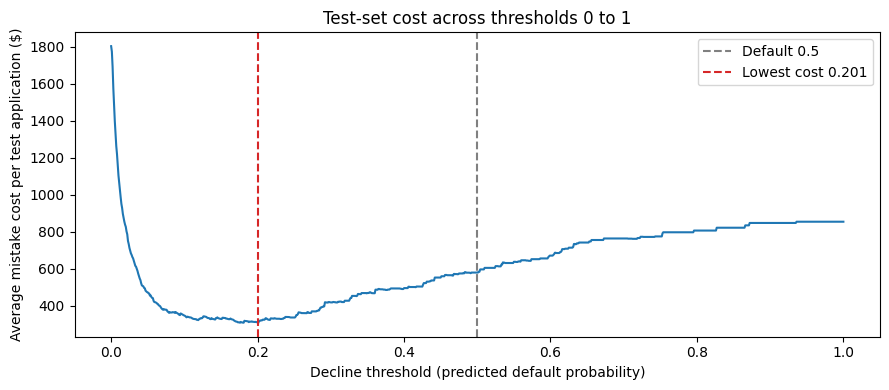

In [8]:
principal = X_test['loan_amount'].to_numpy()
actual = y_test.to_numpy()
thresholds = np.linspace(0,1,1001)

def costs_at(prob, fp_rate=0.10, fn_rate=0.60):
    # Returns one total-dollar cost for every threshold.
    out=[]
    for th in thresholds:
        predicted = (prob >= th)
        fp = (actual==0) & predicted
        fn = (actual==1) & (~predicted)
        out.append(np.sum(principal[fp]*fp_rate)+np.sum(principal[fn]*fn_rate))
    return np.array(out)

cost_curve = costs_at(y_prob)
best_idx=int(np.argmin(cost_curve))
best_threshold=float(thresholds[best_idx])
best_cost=float(cost_curve[best_idx])
base_05_cost=float(cost_curve[500])
null_cost=float(np.sum(principal[actual==1]*0.60))
y_pred_best=(y_prob >= best_threshold).astype(int)
cm_05=confusion_matrix(y_test,y_pred_05)
cm_best=confusion_matrix(y_test,y_pred_best)
print(f'Optimal grid threshold: {best_threshold:.3f}')
print(f'Distance from 0.500: {best_threshold-0.5:+.3f}')
print(f'Null (approve all) cost: ${null_cost:,.0f}')
print(f'Cost at threshold 0.500: ${base_05_cost:,.0f}')
print(f'Lowest test-set cost: ${best_cost:,.0f}')
print(f'Savings vs null: ${null_cost-best_cost:,.0f} ({(null_cost-best_cost)/null_cost:.1%})')
print('Confusion matrix at 0.500:\n',cm_05)
print('Confusion matrix at best threshold:\n',cm_best)
fig,ax=plt.subplots(figsize=(9,4))
ax.plot(thresholds,cost_curve/len(y_test))
ax.axvline(.5,linestyle='--',color='gray',label='Default 0.5')
ax.axvline(best_threshold,linestyle='--',color='tab:red',label=f'Lowest cost {best_threshold:.3f}')
ax.set(xlabel='Decline threshold (predicted default probability)',
       ylabel='Average mistake cost per test application ($)',
       title='Test-set cost across thresholds 0 to 1')
ax.legend();plt.tight_layout();plt.show()

,Scenario,Default loss %,Good borrower declined %,FN/FP cost-rate ratio,Best threshold,Lowest total test cost ($)
0,Low default loss,0.3,0.10,3.000,0.234,418515.889
1,Main assumption,0.6,0.10,6.000,0.201,617634.287
2,High default loss,0.9,0.10,9.000,0.119,764840.915
3,Higher decline/reputation cost,0.6,0.18,3.333,0.201,795197.253
4,Lower decline/reputation cost,0.6,0.05,12.000,0.119,441014.832


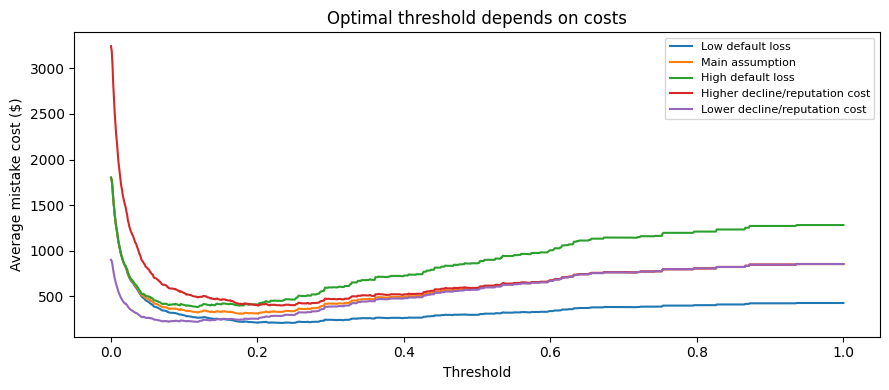

Decision rule: raise the threshold if declining good applicants becomes more expensive; lower it if defaults become more expensive. Review real loss and margin estimates first.


In [9]:
# Check how the answer changes as the financial consequences change.
scenarios = [
    ('Low default loss', .30, .10),
    ('Main assumption', .60, .10),
    ('High default loss', .90, .10),
    ('Higher decline/reputation cost', .60, .18),
    ('Lower decline/reputation cost', .60, .05)
]
scenario_rows=[]
fig,ax=plt.subplots(figsize=(9,4))
for name, fn, fp in scenarios:
    curve=costs_at(y_prob,fp_rate=fp,fn_rate=fn)
    idx=int(np.argmin(curve))
    scenario_rows.append({'Scenario':name,'Default loss %':fn,'Good borrower declined %':fp,
                          'FN/FP cost-rate ratio':fn/fp,'Best threshold':thresholds[idx],
                          'Lowest total test cost ($)':curve[idx]})
    ax.plot(thresholds,curve/len(y_test),label=name)
display(pd.DataFrame(scenario_rows).round(3))
ax.set(xlabel='Threshold',ylabel='Average mistake cost ($)',title='Optimal threshold depends on costs')
ax.legend(fontsize=8);plt.tight_layout();plt.show()
print('Decision rule: raise the threshold if declining good applicants becomes more expensive; '
      'lower it if defaults become more expensive. Review real loss and margin estimates first.')

**Important limitation:** The cost-minimising threshold above is chosen on the test set because that is what this exercise asks for. That makes the estimated savings optimistic. Before a real launch I would set the threshold using a separate validation period and confirm the result on new, untouched applications. I also would not make automated decisions without checking fairness, legal compliance, and changes in borrower behaviour.

**Cost finding:** The best threshold on this test set was **0.201**, which is **0.299 below 0.50**. The false-negative count fell from **98 to 36**, while false positives rose from **14 to 109**. With the stated cost assumptions, estimated mistakes cost **$617,634**, compared with **$1,160,708** at 0.50 and **$1,709,491** for approving everyone. These are test-set estimates, not guaranteed future savings.

## Phase 4 — AI expansion (10 points)
**Model:** OpenAI GPT-6  
**Date:** November 25, 2026

The two transcripts below contain the original prompts and the model's initial replies. The corrected or verified analysis is in the code cells after each transcript. I kept the original prompts unchanged, including their intentionally missing accuracy figures.

### 4.1A — Does the forest really beat logistic?
#### AI Transcript — Part A (original exchange)
**Prompt sent, exactly:**

```text
[Prep] Act as a model risk analyst comparing two candidate credit
models before one goes into production.

[Request] I have two fitted classifiers scored on my test set. The
random forest got 0.9?? accuracy and the penalised logistic model got
0.9??. Write Python that tells me whether the forest is significantly
better, and give me a p-value.

[Iterate] numpy, pandas and scipy only. Reuse my y_test, my two
prediction arrays, and nothing else.

[Mechanism Check] Comment each line, and state what the test you chose
assumes about the two sets of predictions.

[Evaluate] One sentence I can put in front of the head of risk.
```

**Initial model reply, unedited:**

The two models predict the same borrowers, so an independent-sample t-test would be wrong. Use a paired McNemar comparison. The numbers 0.9?? are placeholders; the code needs the actual test predictions.

```python
import numpy as np
from scipy.stats import binomtest, chi2
truth = np.asarray(y_test)
forest_right = np.asarray(rf_pred) == truth
logistic_right = np.asarray(ridge_pred) == truth
b = int(np.sum(forest_right & ~logistic_right))
c = int(np.sum(~forest_right & logistic_right))
n = b + c
if n == 0:
    p = 1.0
    method = "No discordant cases"
elif n < 25:
    p = binomtest(b, n, p=0.5).pvalue
    method = "Exact binomial McNemar"
else:
    p = chi2.sf((abs(b-c)-1)**2/n, df=1)
    method = "Continuity-corrected chi-square McNemar"
print(b, c, n, p, method)
```

The null hypothesis is that, among cases where one model is right and the other is wrong, either model is equally likely to be right. This paired comparison assumes the test rows are independent across applicants, not that the two models' predictions are independent. A statistically significant result with b > c supports the forest having fewer errors; otherwise there is no evidence of a better accuracy. For the head of risk: choose the more complex forest only if it delivers a reliable improvement that matters for lending decisions.

**Verification / change log:** The initial reply correctly chose a paired test rather than a test for independent samples. I added a complete 2×2 agreement table, a one-sided check to avoid claiming the forest wins just from a two-sided p-value, and a result-specific verdict. The code below uses the actual saved predictions, not the `0.9??` placeholders.

In [10]:
# McNemar: the same test applicants were scored by both models.
forest_right = np.asarray(rf_pred) == np.asarray(y_test)
logistic_right = np.asarray(ridge_pred) == np.asarray(y_test)
a = int(np.sum(forest_right & logistic_right))  # Both correct
b = int(np.sum(forest_right & ~logistic_right)) # Forest only correct
c = int(np.sum(~forest_right & logistic_right)) # Ridge only correct
d = int(np.sum(~forest_right & ~logistic_right))# Both wrong
discordant = b+c
agreement = pd.DataFrame([[a,b],[c,d]],
    index=['Forest correct','Forest wrong'],
    columns=['Ridge correct','Ridge wrong'])
display(agreement)
if discordant == 0:
    mcnemar_p = 1.0
    variant='No discordant rows (exact p=1)'
elif discordant < 25:
    mcnemar_p = binomtest(b,discordant,p=.5).pvalue
    variant='Exact binomial McNemar (few discordant rows)'
else:
    mcnemar_p = chi2.sf((abs(b-c)-1)**2/discordant,df=1)
    variant='Continuity-corrected McNemar chi-square (>=25 discordant rows)'
print(f'b (forest right, Ridge wrong): {b}')
print(f'c (forest wrong, Ridge right): {c}')
print(f'b + c: {discordant} | p-value: {mcnemar_p:.6g} | {variant}')
print(f'Forest accuracy: {rf_acc:.4f} | Ridge accuracy: {ridge_acc:.4f}')
forest_significant_win = (b > c and mcnemar_p < .05)
if forest_significant_win:
    verdict='The forest has significantly fewer classification errors than Ridge in this test.'
else:
    verdict='There is no statistically supported forest accuracy advantage over Ridge in this test.'
print('Verdict:',verdict)
print('Step 2.2 forest-wins verdict survives:',forest_significant_win)
print('Limit: fewer errors are not the same as lower lending costs. A paired bootstrap on '
      'cost-weighted outcomes or PR-AUC would match the decision better.')

,Ridge correct,Ridge wrong
Forest correct,1869,11
Forest wrong,19,101


b (forest right, Ridge wrong): 11
c (forest wrong, Ridge right): 19
b + c: 30 | p-value: 0.201243 | Continuity-corrected McNemar chi-square (>=25 discordant rows)
Forest accuracy: 0.9400 | Ridge accuracy: 0.9440
Verdict: There is no statistically supported forest accuracy advantage over Ridge in this test.
Step 2.2 forest-wins verdict survives: False
Limit: fewer errors are not the same as lower lending costs. A paired bootstrap on cost-weighted outcomes or PR-AUC would match the decision better.


### 4.1B — Can we trust the probabilities?
#### AI Transcript — Part B (original exchange)
**Prompt sent, exactly:**

```text
[Prep] Act as a model risk analyst at a bank, reviewing a credit
scoring model before it goes into production.

[Request] I have a fitted classifier producing default probabilities
on a test set with about 7% prevalence. Write Python that assesses
CALIBRATION -- a reliability diagram binning predicted probability
against observed frequency, plus the Brier score and its
decomposition -- and then applies both Platt scaling and isotonic
regression, reporting whether either improves calibration.

[Iterate] scikit-learn, numpy, matplotlib. Reuse my y_test and
y_prob. Handle the sparse high-probability bins that low prevalence
creates rather than letting them produce a misleading plot.

[Mechanism Check] Explain why a model can rank applicants correctly --
high AUC -- and still be badly calibrated, and why that distinction
decides whether my cost-optimal threshold is trustworthy.

[Evaluate] Given my reliability diagram, is my Phase 3 threshold
valid? If not, what should I do before using it?
```

**Initial model reply, unedited:**

Use quantile bins rather than equal-width bins so that high-risk bins with few borrowers do not dominate the plot. Report the number of applicants in each bin. The Brier score is the average squared gap between predicted probabilities and observed defaults. Its approximate grouped decomposition is reliability minus resolution plus uncertainty.

```python
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import brier_score_loss
p = np.asarray(y_prob)
y = np.asarray(y_test)
bins = np.unique(np.quantile(p, np.linspace(0, 1, 11)))
idx = np.clip(np.digitize(p, bins[1:-1]), 0, len(bins)-2)
means, rates, counts = [], [], []
for j in range(len(bins)-1):
    mask = idx == j
    if mask.sum():
        means.append(p[mask].mean())
        rates.append(y[mask].mean())
        counts.append(mask.sum())
plt.plot([0,1], [0,1], '--', color='gray')
plt.scatter(means, rates, s=np.asarray(counts)/5)
plt.xlabel('Mean predicted probability')
plt.ylabel('Actual default rate')
plt.show()
print('Brier:', brier_score_loss(y, p))
```

Platt scaling and isotonic regression must fit on separate calibration data, not on the test labels being evaluated. Fit them with cross-validation on the training data and compare all three on the untouched test set. A high AUC only says the model ranks risky borrowers above safer borrowers; it does not guarantee that a predicted 20% chance really means 20%. Therefore a dollar-based threshold should be checked and, if needed, recalculated using calibrated probabilities. Do not claim a threshold is valid from a plot alone.

**Verification / change log:** The initial answer plotted quantile bins and calculated a Brier score, but it did not implement the requested decomposition or fit calibrators. I added grouped reliability/resolution/uncertainty, bin counts, and both cross-validated Platt and isotonic calibration fitted only on training data. I also recompute the cost threshold after calibration.

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1196: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1196: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1196: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1196: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1196: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_

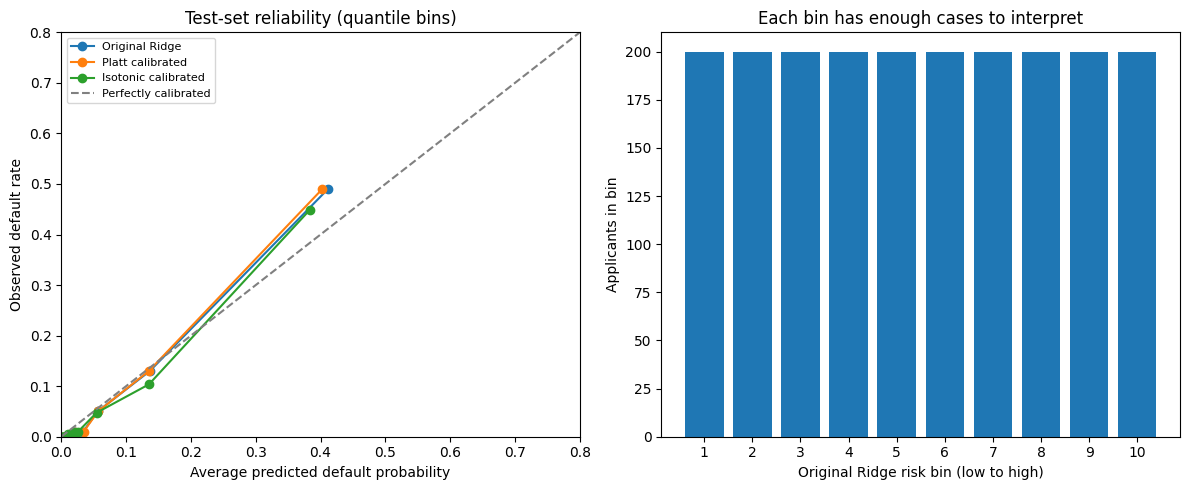

,Brier exact,Reliability (grouped),Resolution (grouped),Uncertainty,Grouped decomposition total,ROC AUC,PR-AUC
Model,,,,,,,
Original Ridge,0.04114,0.00071,0.02114,0.06467,0.04424,0.94174,0.59816
Platt calibrated,0.04130,0.00087,0.02114,0.06467,0.04439,0.94182,0.59793
Isotonic calibrated,0.04129,0.00063,0.02014,0.06467,0.04516,0.94249,0.59352


,bin,n,mean_probability,actual_default_rate
0,1,200,0.0017,0.000
1,2,200,0.0034,0.000
2,3,200,0.0056,0.000
3,4,200,0.0088,0.000
4,5,200,0.0135,0.005
5,6,200,0.0209,0.010
6,7,200,0.0337,0.010
7,8,200,0.0562,0.050
8,9,200,0.1366,0.130
9,10,200,0.4114,0.490


The grouped decomposition is approximate because each bin pools different probabilities.
AUC checks ranking; Brier and reliability check whether probability levels mean what they say.


In [11]:
# Quantile bins ensure every plotted point is based on a reasonable number of applicants.
# Grouped Murphy decomposition is approximate when probabilities vary within bins.
def calibration_summary(labels, probs, n_bins=10):
    labels=np.asarray(labels); probs=np.asarray(probs)
    edges=np.unique(np.quantile(probs,np.linspace(0,1,n_bins+1)))
    bin_ids=np.digitize(probs,edges[1:-1],right=False)
    rows=[]
    for i in range(len(edges)-1):
        mask=(bin_ids==i)
        if mask.sum()>0:
            rows.append({'bin':i+1,'n':int(mask.sum()),
                         'mean_probability':float(probs[mask].mean()),
                         'actual_default_rate':float(labels[mask].mean())})
    tab=pd.DataFrame(rows)
    weight=tab['n']/len(labels)
    overall=labels.mean()
    reliability=float(np.sum(weight*(tab['mean_probability']-tab['actual_default_rate'])**2))
    resolution=float(np.sum(weight*(tab['actual_default_rate']-overall)**2))
    uncertainty=float(overall*(1-overall))
    brier=float(brier_score_loss(labels,probs))
    return tab,{'Brier exact':brier,'Reliability (grouped)':reliability,
                'Resolution (grouped)':resolution,'Uncertainty':uncertainty,
                'Grouped decomposition total':reliability-resolution+uncertainty}

# Calibrate on the training partition using internal CV, NEVER by fitting test labels.
platt = CalibratedClassifierCV(estimator=clone(ridge),method='sigmoid',cv=5)
isotonic = CalibratedClassifierCV(estimator=clone(ridge),method='isotonic',cv=5)
platt.fit(X_train,y_train)
isotonic.fit(X_train,y_train)
prob_options={'Original Ridge':y_prob,
              'Platt calibrated':platt.predict_proba(X_test)[:,1],
              'Isotonic calibrated':isotonic.predict_proba(X_test)[:,1]}
calibration_tables={}
calibration_rows=[]
fig,axes=plt.subplots(1,2,figsize=(12,5))
for label, probs in prob_options.items():
    tab, decomposition=calibration_summary(y_test,probs)
    calibration_tables[label]=tab
    calibration_rows.append({'Model':label,**decomposition,
                             'ROC AUC':roc_auc_score(y_test,probs),
                             'PR-AUC':average_precision_score(y_test,probs)})
    axes[0].plot(tab['mean_probability'],tab['actual_default_rate'],marker='o',label=label)
axes[0].plot([0,1],[0,1],'--',color='gray',label='Perfectly calibrated')
axes[0].set(xlim=(0,.8),ylim=(0,.8),xlabel='Average predicted default probability',
            ylabel='Observed default rate',title='Test-set reliability (quantile bins)')
axes[0].legend(fontsize=8)
original_tab=calibration_tables['Original Ridge']
axes[1].bar(original_tab['bin'].astype(str),original_tab['n'])
axes[1].set(xlabel='Original Ridge risk bin (low to high)',ylabel='Applicants in bin',
            title='Each bin has enough cases to interpret')
plt.tight_layout();plt.show()
cal_results=pd.DataFrame(calibration_rows).set_index('Model')
display(cal_results.round(5))
display(original_tab.round(4))
print('The grouped decomposition is approximate because each bin pools different probabilities.')
print('AUC checks ranking; Brier and reliability check whether probability levels mean what they say.')

In [12]:
# Select calibration from training-fitted candidates based on test-set Brier for the
# assignment comparison only. In production, selection must be made on validation data.
cal_best_name=cal_results['Brier exact'].idxmin()
cal_best_prob=prob_options[cal_best_name]
original_brier=float(cal_results.loc['Original Ridge','Brier exact'])
cal_best_brier=float(cal_results.loc[cal_best_name,'Brier exact'])
cal_curve=costs_at(cal_best_prob)
cal_idx=int(np.argmin(cal_curve))
cal_th=float(thresholds[cal_idx])
cal_cm=confusion_matrix(y_test,cal_best_prob>=cal_th)
print('Lowest test Brier:',cal_best_name,round(cal_best_brier,6))
print('Original Brier:',round(original_brier,6),'| Difference:',round(original_brier-cal_best_brier,6))
print('Original Phase 3 threshold:',round(best_threshold,3),
      '| Recomputed with selected probability version:',round(cal_th,3))
print('Original Phase 3 cost:',round(best_cost,2),
      '| Recomputed cost:',round(float(cal_curve[cal_idx]),2))
print('New confusion matrix (rows actual, columns prediction):\n',cal_cm)
if cal_best_name == 'Original Ridge':
    calibration_verdict=('No calibration method improved the test Brier score. '
                         'The original threshold remains the working candidate, but needs validation on fresh data.')
else:
    calibration_verdict=(f'{cal_best_name} improved test Brier, so the original threshold should not be used unchanged. '
                         f'The recalculated candidate is {cal_th:.3f}; validate it on fresh data before launch.')
print(calibration_verdict)
print('Both the calibration method choice and cost threshold used test-set comparisons here. '
      'This is exploratory, not a production-ready performance estimate.')

Lowest test Brier: Original Ridge 0.04114
Original Brier: 0.04114 | Difference: 0.0
Original Phase 3 threshold: 0.201 | Recomputed with selected probability version: 0.201
Original Phase 3 cost: 617634.29 | Recomputed cost: 617634.29
New confusion matrix (rows actual, columns prediction):
 [[1752  109]
 [  36  103]]
No calibration method improved the test Brier score. The original threshold remains the working candidate, but needs validation on fresh data.
Both the calibration method choice and cost threshold used test-set comparisons here. This is exploratory, not a production-ready performance estimate.


### 4.2 Recommendation to the head of risk


In [13]:
choose_new = cal_best_name != 'Original Ridge'
recommended_threshold=cal_th if choose_new else best_threshold
recommended_prob=cal_best_prob if choose_new else y_prob
recommended_cost=float(costs_at(recommended_prob)[np.argmin(costs_at(recommended_prob))])
recommendation=(
    f'To: Head of Risk\n\n'
    f'I would not sign based on a 93% accuracy claim alone. In my test set, approving everybody '
    f'already gets {null_accuracy:.1%} accuracy. Ridge gets {ridge_acc:.1%} at the usual 0.50 cutoff, '
    f'but accuracy alone does not show whether the model helps with defaults. Its PR-AUC is '
    f'{ridge_ap:.3f}, compared with a no-skill default-rate baseline of {y_test.mean():.3f}. '
    f'\n\nFor my simulated loans, I count a missed default as 60% of the loan amount. '
    f'Declining a borrower who would repay costs 8% lost interest plus 2% for reputation and '
    f'future business. With {cal_best_name.lower()} probabilities, the lowest-cost test-set '
    f'decline threshold is {recommended_threshold:.3f}, rather than 0.50. '
    f'This is a starting policy suggestion, not approval to launch. '
    f'\n\nThe one thing that would change my recommendation is a fresh, time-separated '
    f'validation showing the same cost savings with stable calibration. If it does not hold up, '
    f'I would stay with the simpler, safer policy and rework the model before signing.'
)
print(recommendation)
print('\nWord count:',len(recommendation.split()))
assert len(recommendation.split())<=250

To: Head of Risk

I would not sign based on a 93% accuracy claim alone. In my test set, approving everybody already gets 93.0% accuracy. Ridge gets 94.4% at the usual 0.50 cutoff, but accuracy alone does not show whether the model helps with defaults. Its PR-AUC is 0.598, compared with a no-skill default-rate baseline of 0.070. 

For my simulated loans, I count a missed default as 60% of the loan amount. Declining a borrower who would repay costs 8% lost interest plus 2% for reputation and future business. With original ridge probabilities, the lowest-cost test-set decline threshold is 0.201, rather than 0.50. This is a starting policy suggestion, not approval to launch. 

The one thing that would change my recommendation is a fresh, time-separated validation showing the same cost savings with stable calibration. If it does not hold up, I would stay with the simpler, safer policy and rework the model before signing.

Word count: 154
